In [1]:
import concurrent.futures
import time
import glob

from scipy import ndimage
from scipy.optimize import curve_fit

import astropy.units as u
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyvo
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.table import Table
from astropy.wcs import WCS
import shutil

In [2]:
def spectrum(ra_target, dec_target, folder, aper=False, sq=2):
    allfiles = glob.glob(f'{folder}/*.fits')
    ww, ff, ee = [], [], []
    for a in allfiles:
        hdulist = fits.open(a)
        img = hdulist[1].data
        zodi = hdulist[4].data
        img -= zodi
        wave = hdulist[6].data
        err = np.sqrt(hdulist[3].data)
        spectral_image_header = hdulist[1].header
        wcs = WCS(spectral_image_header)
        ra, dec = wcs.wcs.crval
        x, y = wcs.world_to_pixel(SkyCoord(ra=ra, dec=dec, unit="deg"))
        spectral_wcs = WCS(header=hdulist["IMAGE"].header, fobj=hdulist, key="W")
    
        spectral_wcs.sip = None
        wl, bw = spectral_wcs.pixel_to_world(x, y)
        spectral_image = hdulist["IMAGE"]
        spectral_image_data = spectral_image.data
        (y, x) = np.indices(spectral_image.shape)
        spectral_coords = spectral_wcs.pixel_to_world(x, y)
        wavelength, bandwidth = spectral_coords
    
        coord = SkyCoord(ra=ra_target*u.deg, dec=dec_target*u.deg, frame="icrs")
        
        x, y = wcs.world_to_pixel(coord)
        
        img = hdulist[1].data
        arr = img.copy()
    
        p1, p2 = int(x-80), int(x+80)
        try: 
            flux = img[int(y+0.5),p1:p2]
            ferr = err[int(y+0.5),p1:p2]
            if aper:
                flux = np.mean(img[int(y+0.5)-2:int(y+0.5)+3, p1:p2], axis=0)
            lam = wavelength.value[int(y+0.5),int(x+0.5)]
            print(y, x, lam)
            sm = 2
            flux = ndimage.gaussian_filter1d(flux, sm)
            ferr = ndimage.gaussian_filter1d(ferr, sm) / np.sqrt(2*np.sqrt(np.pi)*sm)
            if aper: 
                a1, a2 = int(y+0.5)-sq, int(y+0.5)+sq
                b1, b2 = int(x+0.5)-sq, int(x+0.5)+sq
                ff.append(np.mean(img[a1:a2,b1:b2]))
                ee.append(np.mean(err[a1:a2,b1:b2]))
            else: ff.append(flux[80]); ee.append(ferr[80])
            ww.append(lam)
        except: 
            #shutil.move(a, 'useless/'+a.split('/')[1])
            continue
    ww, ff, ee = np.array(ww), np.array(ff), np.array(ee)
    ww, ff, ee = np.sort(ww), ff[np.argsort(ww)], ee[np.argsort(ww)]
    mask = np.isnan(ff)
    return ww[~mask], ff[~mask], ee[~mask]

In [3]:
def cont_fit(w,A,B,C):
    return A*w**2 + B*w + C

In [4]:
import warnings
from matplotlib import rcParams
# Ignore all warnings
warnings.filterwarnings('ignore')
rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'mathtext.fontset': 'custom',
    'mathtext.rm': 'Times New Roman',
    'mathtext.it': 'Times New Roman:italic',
    'mathtext.bf': 'Times New Roman:bold',
    'font.size': 14
})

## L1512 - prestellar:

### Fetch pointwise spectra:

In [50]:
rlist = [76.0364167, 76.0454167, 76.0544167]   
dlist = [32.7211667, 32.7151667, 32.7051667]

w1a, f1a, e1a = spectrum(rlist[0], dlist[0], 'L1512-SPHEREx', aper=False)
w2a, f2a, e2a = spectrum(rlist[1], dlist[1], 'L1512-SPHEREx', aper=False)
w3a, f3a, e3a = spectrum(rlist[2], dlist[2], 'L1512-SPHEREx', aper=False)

INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS object.

                 [astropy.wcs.wcs]
1062.4461713558462 5

### Plot spectra and error bands:

In [ ]:
collist = ['firebrick', 'orangered', 'gold']
namelist = ['Core centre', 'Intermediate $r$' , 'Outskirts']
fig, ax = plt.subplots(3, 1, figsize=(5,4), dpi=200, sharex=True, gridspec_kw={"wspace": 0.0, "hspace": 0.08})

for ww, ff, ee, cc, nn, ctr in zip([w1, w2, w3], [f1, f2, f3], [e1, e2, e3], collist, namelist, [0,1,2]):
    wv, fv, ev = ww.copy(), ff.copy(), ee.copy()
    mask = np.isnan(fv) | (fv < 0)
    wv, fv, ev = wv[~mask], fv[~mask], ev[~mask]
    mask = np.where((wv <= 2.7) | ((wv >= 3.6) & (wv <= 4.)))[0]
    popt, pcov = curve_fit(cont_fit, wv[mask], fv[mask])
    perr = np.sqrt(np.diag(pcov))
    cont = cont_fit(wv, *popt)
    if 1:
        y1 = fv 
        y2 = (fv-ev)  
        y3 = (fv+ev)   
    mask = np.where(((wv >= 2.9) & (wv <= 3.1)) & ~np.isnan(fv))[0]
    tau_all = -np.log(fv[mask] / cont[mask])
    J = np.empty((tau_all.size, popt.size))
    for i, idx in enumerate(np.where(((wv >= 2.9) & (wv <= 3.1)) & ~np.isnan(fv))[0]):
        eps = 1e-6
        for j in range(popt.size):
            dp = np.zeros_like(popt)
            dp[j] = eps
            cont_p = cont_fit(wv[idx], *(popt + dp))
            cont_m = cont_fit(wv[idx], *(popt - dp))
            dcont_dp = (cont_p - cont_m)/(2*eps)
            J[i, j] = (dcont_dp/cont[idx])
    tau_fit_var = np.einsum('ij,jk,ik->i', J, pcov, J)
    tau_data_var = (ev[~mask]/fv[~mask])**2
    tau_mean = np.nanmean(tau_all)
    N = tau_all.size
    tau_all_var = tau_fit_var + tau_data_var          
    tau_var_mean = np.nanmean(tau_all_var)            
    tau_err = np.sqrt(tau_var_mean / N)        

    tauprint = r'$\tau = $' + str(np.round(tau_mean, 2)) + r'$\pm$' + str(np.round(tau_err, 2))
    #plt.plot(wv, fv, marker='', color=cc, label=)
    #plt.plot(wv, cont, color='grey', ls='--')
    plotmask = wv <= 4.
    ax[ctr].plot(wv[plotmask], y1[plotmask], marker='', color=cc, label=nn)
    ax[ctr].fill_between(wv[plotmask], y2[plotmask], y3[plotmask], color=cc, alpha=0.5, edgecolor='None')
    ax[ctr].plot(wv[plotmask], cont[plotmask], color=cc, lw=3, ls='--')
    if ctr < 2: ax[ctr].legend(loc='lower right')
    else: ax[ctr].legend(loc='upper right')
#plt.show()
#

if 0:
    plt.plot(w1, f1, marker='d', label='Centre')
    plt.plot(w2, f2, marker='d', label='Middle')
    plt.plot(w3, f3, marker='d', label='Outskirts')
plt.xlabel(r'Wavelength [$\mu$m]')
fig.supylabel('Flux [MJy/Sr]', x=-0.03, fontsize=15)
#plt.axhline(0, color='k', alpha=0.4,ls='--')
#plt.title('Continuum-Normalized Flux')
#plt.gca().invert_yaxis()
plt.tight_layout()
#plt.title('CrA 151 Sightlines')
plt.savefig('Paper1.2/L1512-threepoints-spec.pdf', bbox_inches='tight', pad_inches=0)
#plt.ylim(0,1.5)

### Plot Optical Depths:

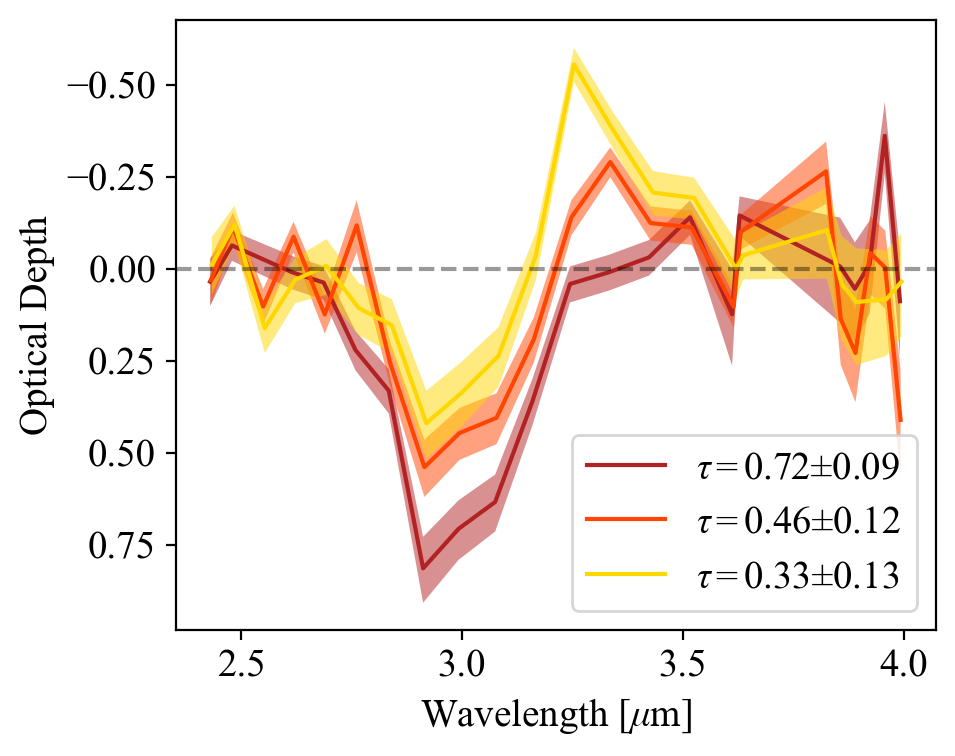

In [201]:
#plt.plot(w1, f1/np.nanmedian(f1[:4]), marker='d')
#plt.plot(w1, f1, marker='d')
f1a[2] = np.nan
#f2[3] = np.nan
#f3[-6] = np.nan


collist = ['firebrick', 'orangered', 'gold']
namelist = ['Core centre', 'Intermediate $r$' , 'Outskirts']
plt.figure(figsize=(5,4), dpi=200)
for ww, ff, ee, cc, nn in zip([w1a, w2a, w3a], [f1a, f2a, f3a], [e1a, e2a, e3a], collist, namelist):
    wv, fv, ev = ww.copy(), ff.copy(), ee.copy()
    mask = np.isnan(fv) | (fv<0)
    wv, fv, ev = wv[~mask], fv[~mask], ev[~mask]
    mask = np.where((wv <= 2.7) | ((wv >= 3.6) & (wv <= 3.95)))[0]
    popt, pcov = curve_fit(cont_fit, wv[mask], fv[mask])
    perr = np.sqrt(np.diag(pcov))
    cont = cont_fit(wv, *popt)
    y1 = (fv - cont)/np.nanmedian(fv[:6]) + 1
    y2 = (fv - ev - cont)/np.nanmedian(fv[:6]) + 1
    y3 = (fv + ev - cont)/np.nanmedian(fv[:6]) + 1
    if 1:
        y1 = -np.log(fv /cont )#; y1=fv
        y2 = -np.log((fv-ev) /cont )#; y2 = fv-ev 
        y3 = -np.log((fv+ev) /cont )#; y3 = fv+ev
    mask = np.where(((wv >= 2.9) & (wv <= 3.1)) & ~np.isnan(fv))[0]
    tau_all = -np.log(fv[mask] / cont[mask])
    J = np.empty((tau_all.size, popt.size))
    for i, idx in enumerate(np.where(((wv >= 2.9) & (wv <= 3.1)) & ~np.isnan(fv))[0]):
        eps = 1e-6
        for j in range(popt.size):
            dp = np.zeros_like(popt)
            dp[j] = eps
            cont_p = cont_fit(wv[idx], *(popt + dp))
            cont_m = cont_fit(wv[idx], *(popt - dp))
            dcont_dp = (cont_p - cont_m)/(2*eps)
            J[i, j] = (dcont_dp/cont[idx])
    tau_fit_var = np.einsum('ij,jk,ik->i', J, pcov, J)
    tau_data_var = (ev[~mask]/fv[~mask])**2
    tau_mean = np.nanmean(tau_all)
    N = tau_all.size
    tau_all_var = tau_fit_var + tau_data_var          
    tau_var_mean = np.nanmean(tau_all_var)            
    tau_err = np.sqrt(tau_var_mean / N)        

    
    #plt.plot(wv, y1, marker='', color=cc, label=r'$\tau = $' + str(np.round(tau_mean, 2)) +
    #          r'$\pm$' + str(np.round(tau_err, 2)))
    tauprint = r'$\tau = $' + str(np.round(tau_mean, 2)) + r'$\pm$' + str(np.round(tau_err, 2))
    plotmask = wv < 4.
    plt.plot(wv[plotmask], y1[plotmask], marker='', color=cc, label=tauprint)
    plt.fill_between(wv[plotmask], y2[plotmask], y3[plotmask], color=cc, alpha=0.5, edgecolor='None')
plt.ylabel('Optical Depth')
plt.axhline(0, color='k', alpha=0.4,ls='--')
plt.gca().invert_yaxis()

if 0:
    plt.plot(w1, f1/np.nanmedian(f1[-6:]), marker='d', label='Centre')
    plt.plot(w2, f2/np.nanmedian(f2[-6:]), marker='d', label='Middle')
    plt.plot(w3, f3/np.nanmedian(f3[-6:]), marker='d', label='Outskirts')
plt.xlabel(r'Wavelength [$\mu$m]')
#plt.ylabel('Relative Flux')
#plt.title('Median-Normalised Flux')
plt.legend()
plt.tight_layout()
plt.savefig('Paper1.2/L1512-threepoints.pdf', bbox_inches='tight', pad_inches=0)
#plt.ylim(0,1.5)

In [45]:
rlist = [285.4102500, 285.4602500, 285.4502500, 285.4302500]
dlist = [-36.9602500, -36.9362500, -36.9362500, -36.9362500]

rlist = [285.4602500, 285.4802500, 285.5102500]
dlist = [-36.9362500, -36.9052500, -36.8852500]

rlist = [285.4602500, 285.5002500, 285.4882500]
dlist = [-36.9362500, -36.9602500, -36.9422500]

#dlist = [-36.945, -36.945, -36.945, -36.945]
w1, f1, e1 = spectrum(rlist[0], dlist[0], 'RCrA-SPHEREx')
w2, f2, e2 = spectrum(rlist[1], dlist[1], 'RCrA-SPHEREx')
w3, f3, e3 = spectrum(rlist[2], dlist[2], 'RCrA-SPHEREx')
#w4, f4, e4 = spectrum(rlist[3], dlist[3], 'RCrA-SPHEREx')

INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS object.

                 [astropy.wcs.wcs]
183.34242152340778 1

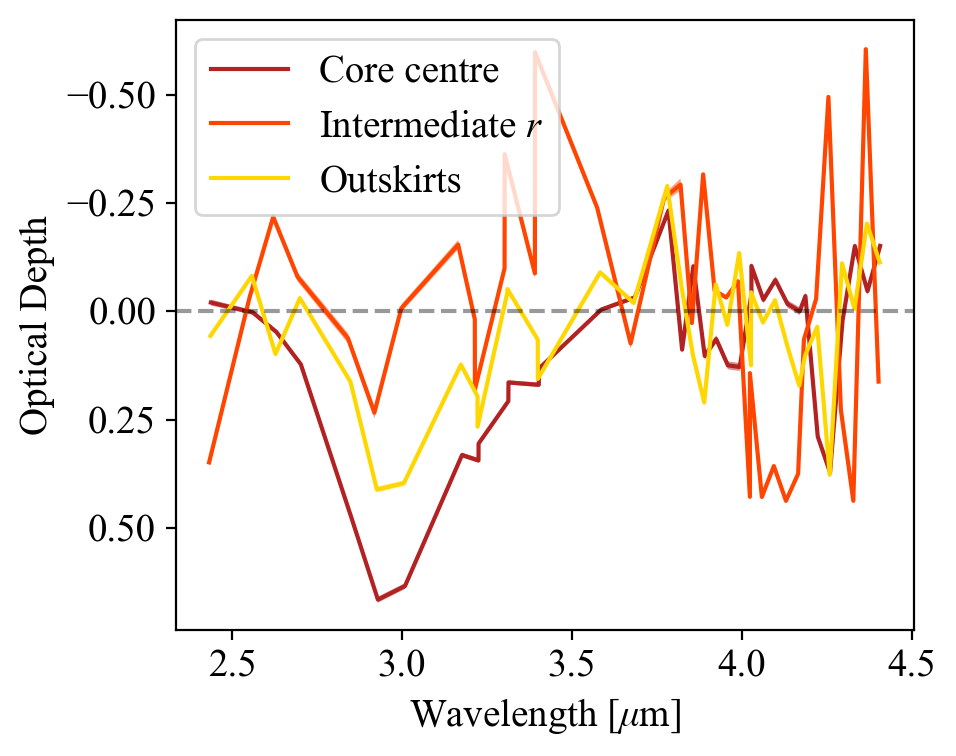

In [46]:
#f3[1] = np.nan

collist = ['firebrick', 'orangered', 'gold']
namelist = ['Core centre', 'Intermediate $r$' , 'Outskirts']
plt.figure(figsize=(5,4), dpi=200)
for ww, ff, ee, cc, nn in zip([w1, w2, w3], [f1, f2, f3], [e1, e2, e3], collist, namelist):
    wv, fv, ev = ww.copy(), ff.copy(), ee.copy()
    mask = np.isnan(fv)
    wv, fv, ev = wv[~mask], fv[~mask], ev[~mask]
    mask = np.where((wv <= 2.7) | (wv >= 3.6))[0]
    popt, pcov = curve_fit(cont_fit, wv[mask], fv[mask])
    perr = np.sqrt(np.diag(pcov))
    cont = cont_fit(wv, *popt)
    y1 = (fv - cont)/np.nanmedian(fv[:6]) + 1
    y2 = (fv - ev - cont)/np.nanmedian(fv[:6]) + 1
    y3 = (fv + ev - cont)/np.nanmedian(fv[:6]) + 1
    if 1:
        y1 = -np.log(fv /cont )#; y1=fv
        y2 = -np.log((fv-ev) /cont )#; y2 = fv-ev 
        y3 = -np.log((fv+ev) /cont )#; y3 = fv+ev
    mask = np.where(((wv >= 2.9) & (wv <= 3.1)) & ~np.isnan(fv))[0]
    tau_all = -np.log(fv[mask] / cont[mask])
    J = np.empty((tau_all.size, popt.size))
    for i, idx in enumerate(np.where(((wv >= 2.9) & (wv <= 3.1)) & ~np.isnan(fv))[0]):
        eps = 1e-6
        for j in range(popt.size):
            dp = np.zeros_like(popt)
            dp[j] = eps
            cont_p = cont_fit(wv[idx], *(popt + dp))
            cont_m = cont_fit(wv[idx], *(popt - dp))
            dcont_dp = (cont_p - cont_m)/(2*eps)
            J[i, j] = (dcont_dp/cont[idx])
    tau_fit_var = np.einsum('ij,jk,ik->i', J, pcov, J)
    tau_data_var = (ev[~mask]/fv[~mask])**2
    tau_mean = np.nanmean(tau_all)
    N = tau_all.size
    tau_all_var = tau_fit_var + tau_data_var          
    tau_var_mean = np.nanmean(tau_all_var)            
    tau_err = np.sqrt(tau_var_mean / N)        

    
    #plt.plot(wv, y1, marker='', color=cc, label=r'$\tau = $' + str(np.round(tau_mean, 2)) +
    #          r'$\pm$' + str(np.round(tau_err, 2)))
    #plt.plot(wv, cont, color=cc, ls='--')
    plt.plot(wv, y1, marker='', color=cc, label=nn)
    plt.fill_between(wv, y2, y3, color=cc, alpha=0.5, edgecolor='None')
plt.ylabel('Optical Depth')
plt.axhline(0, color='k', alpha=0.4,ls='--')
plt.gca().invert_yaxis()
if 0:
    plt.plot(w1, f1/np.nanmedian(f1[-6:]), marker='d', label='Centre')
    plt.plot(w2, f2/np.nanmedian(f2[-6:]), marker='d', label='Middle')
    plt.plot(w3, f3/np.nanmedian(f3[-6:]), marker='d', label='Outskirts')
plt.xlabel(r'Wavelength [$\mu$m]')
#plt.ylabel('Relative Flux')
#plt.title('Median-Normalised Flux')
plt.legend()
plt.tight_layout()
plt.savefig('Paper1.2/R-CrA-threepoints.pdf', bbox_inches='tight', pad_inches=0)
#plt.ylim(0,1.5)

## LDN 260 - prestellar:

In [51]:
rlist = [251.725, 251.7425000, 251.78, 251.78]   
dlist = [-9.62, -9.6055556, -9.595, -9.595]
rlist = [251.7885000, 251.799, 251.810]   
dlist = [-9.5835556, -9.578, -9.572]
w1b, f1b, e1b = spectrum(rlist[0], dlist[0], 'LDN260-SPHEREx')
w2b, f2b, e2b = spectrum(rlist[1], dlist[1], 'LDN260-SPHEREx')
w3b, f3b, e3b = spectrum(rlist[2], dlist[2], 'LDN260-SPHEREx')


INFO: 
                Inconsistent SIP distortion information is present in the FITS header and the WCS object:
                SIP coefficients were detected, but CTYPE is missing a "-SIP" suffix.
                astropy.wcs is using the SIP distortion coefficients,
                therefore the coordinates calculated here might be incorrect.

                If you do not want to apply the SIP distortion coefficients,
                please remove the SIP coefficients from the FITS header or the
                WCS object.  As an example, if the image is already distortion-corrected
                (e.g., drizzled) then distortion components should not apply and the SIP
                coefficients should be removed.

                While the SIP distortion coefficients are being applied here, if that was indeed the intent,
                for consistency please append "-SIP" to the CTYPE in the FITS header or the WCS object.

                 [astropy.wcs.wcs]
1770.3737370588904 5

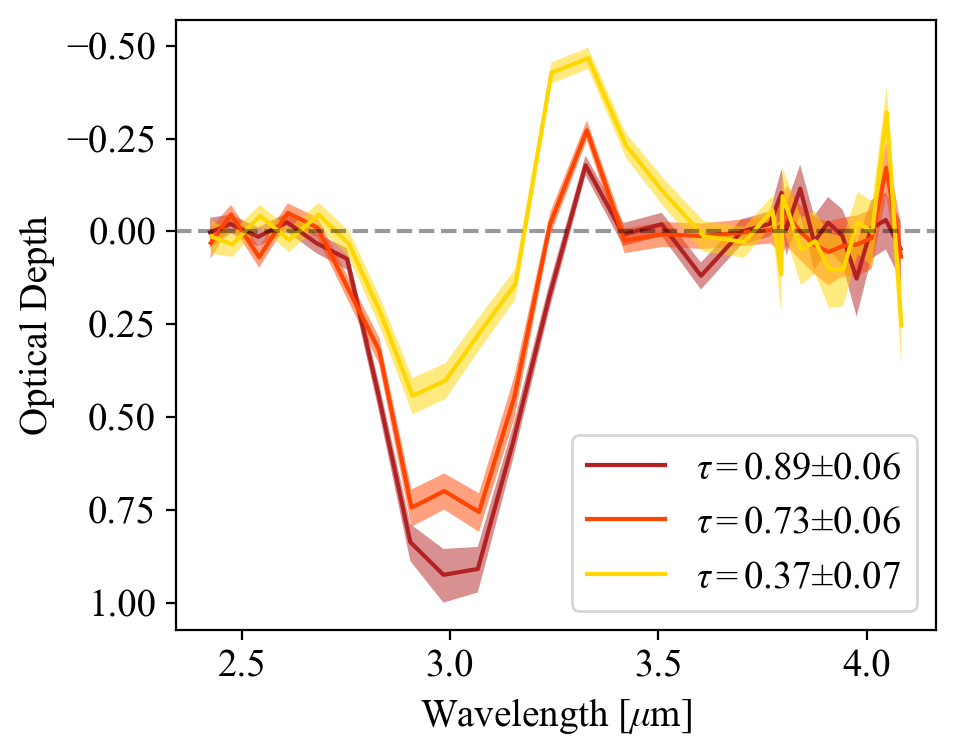

In [203]:
#plt.plot(w1, f1/np.nanmedian(f1[:4]), marker='d')
#plt.plot(w1, f1, marker='d')
#f1[2] = np.nan
#f2[3] = np.nan
#f3[-6] = np.nan
f1b[0] = f2b[0] = f3b[0] = np.nan

collist = ['firebrick', 'orangered', 'gold']
namelist = ['Core centre', 'Intermediate $r$' , 'Outskirts']
plt.figure(figsize=(5,4), dpi=200)
for ww, ff, ee, cc, nn in zip([w1b, w2b, w3b], [f1b, f2b, f3b], [e1b, e2b, e3b], collist, namelist):
    wv, fv, ev = ww.copy(), ff.copy(), ee.copy()
    mask = np.isnan(fv)
    wv, fv, ev = wv[~mask], fv[~mask], ev[~mask]
    mask = np.where((wv <= 2.7) | ((wv >= 3.6) & (wv <= 4.1)))[0]
    popt, pcov = curve_fit(cont_fit, wv[mask], fv[mask])
    perr = np.sqrt(np.diag(pcov))
    cont = cont_fit(wv, *popt)
    y1 = (fv - cont)/np.nanmedian(fv[:6]) + 1
    y2 = (fv - ev - cont)/np.nanmedian(fv[:6]) + 1
    y3 = (fv + ev - cont)/np.nanmedian(fv[:6]) + 1
    if 1:
        y1 = -np.log(fv /cont )#; y1=fv
        y2 = -np.log((fv-ev) /cont )#; y2 = fv-ev 
        y3 = -np.log((fv+ev) /cont )#; y3 = fv+ev
    mask = np.where(((wv >= 2.9) & (wv <= 3.1)) & ~np.isnan(fv))[0]
    tau_all = -np.log(fv[mask] / cont[mask])
    J = np.empty((tau_all.size, popt.size))
    for i, idx in enumerate(np.where(((wv >= 2.9) & (wv <= 3.1)) & ~np.isnan(fv))[0]):
        eps = 1e-6
        for j in range(popt.size):
            dp = np.zeros_like(popt)
            dp[j] = eps
            cont_p = cont_fit(wv[idx], *(popt + dp))
            cont_m = cont_fit(wv[idx], *(popt - dp))
            dcont_dp = (cont_p - cont_m)/(2*eps)
            J[i, j] = (dcont_dp/cont[idx])
    tau_fit_var = np.einsum('ij,jk,ik->i', J, pcov, J)
    tau_data_var = (ev[~mask]/fv[~mask])**2
    tau_mean = np.nanmean(tau_all)
    N = tau_all.size
    tau_all_var = tau_fit_var + tau_data_var          
    tau_var_mean = np.nanmean(tau_all_var)            
    tau_err = np.sqrt(tau_var_mean / N)        

    
    #plt.plot(wv, y1, marker='', color=cc, label=r'$\tau = $' + str(np.round(tau_mean, 2)) +
    #          r'$\pm$' + str(np.round(tau_err, 2)))
    #plt.plot(wv, cont, color=cc, ls='--')
    
    tauprint = r'$\tau = $' + str(np.round(tau_mean, 2)) + r'$\pm$' + str(np.round(tau_err, 2))
    plotmask = wv < 4.1
    plt.plot(wv[plotmask], y1[plotmask], marker='', color=cc, label=tauprint)
    plt.fill_between(wv[plotmask], y2[plotmask], y3[plotmask], color=cc, alpha=0.5, edgecolor='None')
plt.ylabel('Optical Depth')
plt.gca().invert_yaxis()
plt.axhline(0, color='k', alpha=0.4,ls='--')

if 0:
    plt.plot(w1, f1/np.nanmedian(f1[-6:]), marker='d', label='Centre')
    plt.plot(w2, f2/np.nanmedian(f2[-6:]), marker='d', label='Middle')
    plt.plot(w3, f3/np.nanmedian(f3[-6:]), marker='d', label='Outskirts')
plt.xlabel(r'Wavelength [$\mu$m]')
#plt.ylabel('Relative Flux')
#plt.title('Median-Normalised Flux')
plt.legend()
plt.tight_layout()
plt.savefig('Paper1.2/L260-threepoints.pdf', bbox_inches='tight', pad_inches=0)
#plt.ylim(0,1.5)

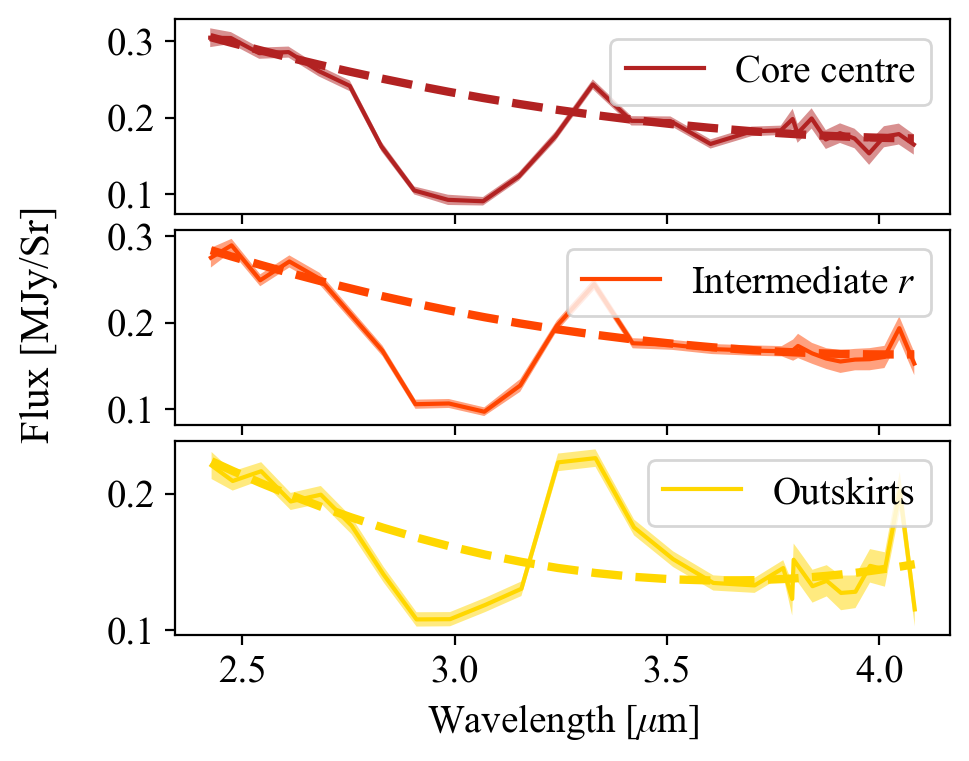

In [190]:



collist = ['firebrick', 'orangered', 'gold']
namelist = ['Core centre', 'Intermediate $r$' , 'Outskirts']
fig, ax = plt.subplots(3, 1, figsize=(5,4), dpi=200, sharex=True, gridspec_kw={"wspace": 0.0, "hspace": 0.08})

for ww, ff, ee, cc, nn, ctr in zip([w1, w2, w3], [f1, f2, f3], [e1, e2, e3], collist, namelist, [0,1,2]):
    wv, fv, ev = ww.copy(), ff.copy(), ee.copy()
    mask = np.isnan(fv) | (fv < 0)
    wv, fv, ev = wv[~mask], fv[~mask], ev[~mask]
    mask = np.where((wv <= 2.7) | ((wv >= 3.6) & (wv <= 4.1)))[0]
    popt, pcov = curve_fit(cont_fit, wv[mask], fv[mask])
    perr = np.sqrt(np.diag(pcov))
    cont = cont_fit(wv, *popt)
    if 1:
        y1 = fv 
        y2 = (fv-ev)  
        y3 = (fv+ev)   
    mask = np.where(((wv >= 2.9) & (wv <= 3.1)) & ~np.isnan(fv))[0]
    tau_all = -np.log(fv[mask] / cont[mask])
    J = np.empty((tau_all.size, popt.size))
    for i, idx in enumerate(np.where(((wv >= 2.9) & (wv <= 3.1)) & ~np.isnan(fv))[0]):
        eps = 1e-6
        for j in range(popt.size):
            dp = np.zeros_like(popt)
            dp[j] = eps
            cont_p = cont_fit(wv[idx], *(popt + dp))
            cont_m = cont_fit(wv[idx], *(popt - dp))
            dcont_dp = (cont_p - cont_m)/(2*eps)
            J[i, j] = (dcont_dp/cont[idx])
    tau_fit_var = np.einsum('ij,jk,ik->i', J, pcov, J)
    tau_data_var = (ev[~mask]/fv[~mask])**2
    tau_mean = np.nanmean(tau_all)
    N = tau_all.size
    tau_all_var = tau_fit_var + tau_data_var          
    tau_var_mean = np.nanmean(tau_all_var)            
    tau_err = np.sqrt(tau_var_mean / N)        

    tauprint = r'$\tau = $' + str(np.round(tau_mean, 2)) + r'$\pm$' + str(np.round(tau_err, 2))
    #plt.plot(wv, fv, marker='', color=cc, label=)
    #plt.plot(wv, cont, color='grey', ls='--')
    plotmask = wv <= 4.1
    ax[ctr].plot(wv[plotmask], y1[plotmask], marker='', color=cc, label=nn)
    ax[ctr].fill_between(wv[plotmask], y2[plotmask], y3[plotmask], color=cc, alpha=0.5, edgecolor='None')
    ax[ctr].plot(wv[plotmask], cont[plotmask], color=cc, lw=3, ls='--')
    if ctr < 2: ax[ctr].legend(loc='upper right')
    else: ax[ctr].legend(loc='upper right')
#plt.show()
#

if 0:
    plt.plot(w1, f1, marker='d', label='Centre')
    plt.plot(w2, f2, marker='d', label='Middle')
    plt.plot(w3, f3, marker='d', label='Outskirts')
plt.xlabel(r'Wavelength [$\mu$m]')
fig.supylabel('Flux [MJy/Sr]', x=-0.03, fontsize=15)
#plt.axhline(0, color='k', alpha=0.4,ls='--')
#plt.title('Continuum-Normalized Flux')
#plt.gca().invert_yaxis()
plt.tight_layout()
#plt.title('CrA 151 Sightlines')
plt.savefig('Paper1.2/L260-threepoints-spec.pdf', bbox_inches='tight', pad_inches=0)
#plt.ylim(0,1.5)